In [10]:
# Cell 1: 环境准备与随机种子固定
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import math

# 固定随机种子，确保结果可复现 (作业要求)
torch.manual_seed(42)
np.random.seed(42)

# 检查设备，如果有显卡就用 GPU，没有就用 CPU (Colab 免费版同理)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"当前使用的设备: {device}")

当前使用的设备: cpu


In [11]:
# Cell 2: 准备序列反转数据
import torch
from torch.utils.data import DataLoader, TensorDataset

# 参数设置
vocab_size = 20     # 词表大小 (数字 0-19)
seq_len = 10        # 序列长度
num_samples = 2000  # 样本数量
batch_size = 64

# 随机生成数据
# 形状: [num_samples, seq_len]
inputs = torch.randint(1, vocab_size, (num_samples, seq_len))
# 目标是输入的反转
targets = torch.flip(inputs, dims=[1])

# 构建 DataLoader
dataset = TensorDataset(inputs, targets)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

print(f"数据准备完毕。输入形状: {inputs.shape}, 目标形状: {targets.shape}")

数据准备完毕。输入形状: torch.Size([2000, 10]), 目标形状: torch.Size([2000, 10])


In [12]:
# Cell 3: 手写缩放点积注意力
import math

def scaled_dot_product_attention(Q, K, V, mask=None):
    # 1. 计算 Q 和 K 的点积
    # Q: [batch, heads, seq_len, head_dim], K: [batch, heads, seq_len, head_dim]
    # K.transpose(-2, -1) 变为 [batch, heads, head_dim, seq_len]
    # scores: [batch, heads, seq_len, seq_len]
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(Q.size(-1))
    
    # 2. 应用因果 Mask (Causal Mask)
    if mask is not None:
        # 将 mask==0 的位置填充为负无穷，这样 softmax 后概率趋近于 0
        scores = scores.masked_fill(mask == 0, float('-inf'))
    
    # 3. Softmax 得到注意力权重
    attn_weights = torch.softmax(scores, dim=-1)
    
    # 4. 乘以 V
    output = torch.matmul(attn_weights, V)
    
    return output, attn_weights

# 生成一个下三角 Mask (因果掩码)
def generate_causal_mask(seq_len, device):
    # torch.tril 生成下三角矩阵
    mask = torch.tril(torch.ones(seq_len, seq_len, device=device)).bool()
    return mask

In [13]:
# Cell 4: 手写多头注意力
import torch.nn as nn

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "d_model 必须能被 num_heads 整除"
        
        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads
        
        # Q, K, V 的线性映射层
        self.q_linear = nn.Linear(d_model, d_model)
        self.k_linear = nn.Linear(d_model, d_model)
        self.v_linear = nn.Linear(d_model, d_model)
        
        # 输出线性层
        self.out_linear = nn.Linear(d_model, d_model)
        
    def forward(self, x, mask=None):
        batch_size, seq_len, _ = x.size()
        
        # 1. 线性映射并拆分成多头
        # 形状变化: [batch, seq_len, d_model] -> [batch, seq_len, heads, head_dim] -> [batch, heads, seq_len, head_dim]
        Q = self.q_linear(x).view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        K = self.k_linear(x).view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        V = self.v_linear(x).view(batch_size, seq_len, self.num_heads, self.head_dim).transpose(1, 2)
        
        # 2. 计算注意力
        # mask 需要扩展维度以匹配 Q, K 的形状: [batch, 1, seq_len, seq_len]
        if mask is not None:
            mask = mask.unsqueeze(0).unsqueeze(0)
            
        out, attn_weights = scaled_dot_product_attention(Q, K, V, mask)
        
        # 3. 拼接多头
        # 形状变化: [batch, heads, seq_len, head_dim] -> [batch, seq_len, heads, head_dim] -> [batch, seq_len, d_model]
        out = out.transpose(1, 2).contiguous().view(batch_size, seq_len, self.d_model)
        
        # 4. 最后的线性层
        out = self.out_linear(out)
        return out, attn_weights

In [14]:
# Cell 5: 位置编码与 Transformer Block
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0) # [1, max_len, d_model]
        self.register_buffer('pe', pe)

    def forward(self, x):
        # x: [batch, seq_len, d_model]
        return x + self.pe[:, :x.size(1), :]

class TransformerBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attention = MultiHeadAttention(d_model, num_heads)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        
        # 前馈网络 FFN
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model)
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # 1. 多头注意力 + 残差连接 + LayerNorm (Post-LN 结构)
        attn_out, attn_weights = self.attention(x, mask)
        x = self.norm1(x + self.dropout(attn_out))
        
        # 2. FFN + 残差连接 + LayerNorm
        ffn_out = self.ffn(x)
        x = self.norm2(x + self.dropout(ffn_out))
        
        return x, attn_weights

In [15]:
# Cell 6: 组装完整模型
class ToyTransformer(nn.Module):
    def __init__(self, vocab_size, d_model, num_heads, num_layers, d_ff, max_len=100):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(d_model, max_len)
        
        # 堆叠多个 Block
        self.layers = nn.ModuleList([
            TransformerBlock(d_model, num_heads, d_ff) for _ in range(num_layers)
        ])
        
        # 最后的输出层映射到词表大小
        self.fc_out = nn.Linear(d_model, vocab_size)

    def forward(self, x, mask=None):
        # x: [batch, seq_len]
        x = self.embedding(x)
        x = self.pos_encoding(x)
        
        all_attn_weights = []
        for layer in self.layers:
            x, attn_weights = layer(x, mask)
            all_attn_weights.append(attn_weights)
            
        logits = self.fc_out(x)
        return logits, all_attn_weights

# 实例化模型
d_model = 64
num_heads = 4
num_layers = 2
d_ff = 256

model = ToyTransformer(vocab_size, d_model, num_heads, num_layers, d_ff).to(device)
print(model)

ToyTransformer(
  (embedding): Embedding(20, 64)
  (pos_encoding): PositionalEncoding()
  (layers): ModuleList(
    (0-1): 2 x TransformerBlock(
      (attention): MultiHeadAttention(
        (q_linear): Linear(in_features=64, out_features=64, bias=True)
        (k_linear): Linear(in_features=64, out_features=64, bias=True)
        (v_linear): Linear(in_features=64, out_features=64, bias=True)
        (out_linear): Linear(in_features=64, out_features=64, bias=True)
      )
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (ffn): Sequential(
        (0): Linear(in_features=64, out_features=256, bias=True)
        (1): ReLU()
        (2): Linear(in_features=256, out_features=64, bias=True)
      )
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (fc_out): Linear(in_features=64, out_features=20, bias=True)
)


In [16]:
# Cell 7: 训练循环
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 15
loss_history = []

model.train()
for epoch in range(epochs):
    epoch_loss = 0
    correct = 0
    total = 0
    
    for batch_x, batch_y in dataloader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        # 生成当前 batch 的 Causal Mask
        mask = generate_causal_mask(seq_len, device)
        
        optimizer.zero_grad()
        logits, _ = model(batch_x, mask)
        
        # CrossEntropyLoss 需要输入形状 [batch*seq_len, vocab_size] 和 [batch*seq_len]
        loss = criterion(logits.view(-1, vocab_size), batch_y.view(-1))
        
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        
        # 计算准确率
        preds = torch.argmax(logits, dim=-1)
        correct += (preds == batch_y).sum().item()
        total += batch_y.numel()
        
    avg_loss = epoch_loss / len(dataloader)
    acc = correct / total
    loss_history.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {avg_loss:.4f} | Acc: {acc*100:.2f}%")

Epoch [1/15] | Loss: 2.9671 | Acc: 6.77%
Epoch [2/15] | Loss: 2.8330 | Acc: 13.49%
Epoch [3/15] | Loss: 2.6308 | Acc: 19.23%
Epoch [4/15] | Loss: 2.2356 | Acc: 31.46%
Epoch [5/15] | Loss: 1.7888 | Acc: 46.60%
Epoch [6/15] | Loss: 1.5812 | Acc: 51.81%
Epoch [7/15] | Loss: 1.5311 | Acc: 52.53%
Epoch [8/15] | Loss: 1.5141 | Acc: 52.72%
Epoch [9/15] | Loss: 1.5121 | Acc: 52.61%
Epoch [10/15] | Loss: 1.5088 | Acc: 52.64%
Epoch [11/15] | Loss: 1.4959 | Acc: 52.86%
Epoch [12/15] | Loss: 1.4906 | Acc: 52.89%
Epoch [13/15] | Loss: 1.4888 | Acc: 53.08%
Epoch [14/15] | Loss: 1.4863 | Acc: 53.01%
Epoch [15/15] | Loss: 1.4946 | Acc: 52.94%


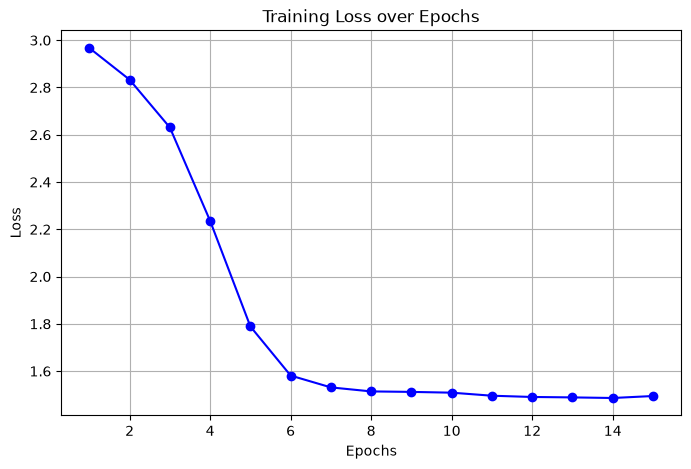

In [17]:
# Cell 8: 绘制 Loss 曲线
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs+1), loss_history, marker='o', color='b')
plt.title('Training Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

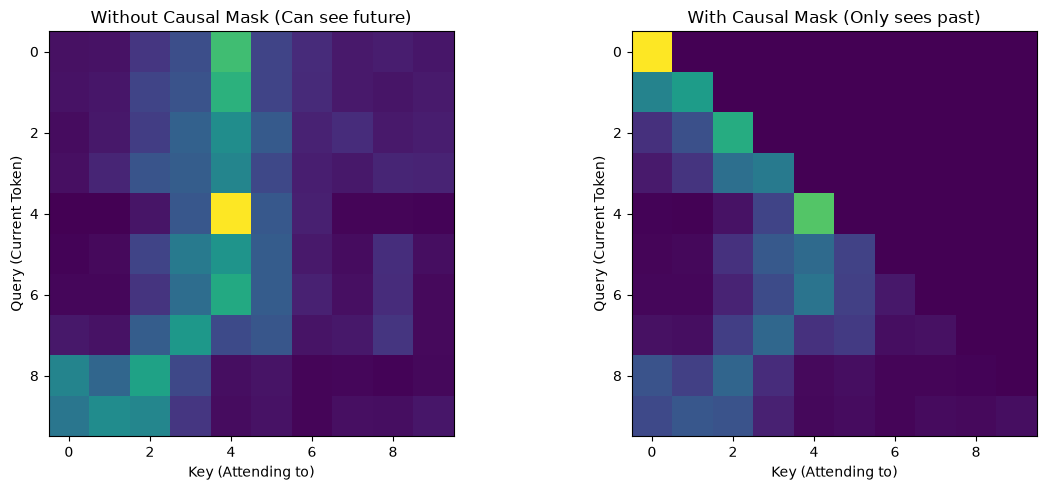

输入序列: [16, 14, 12, 15, 3, 15, 16, 7, 6, 14]
预期反转: [14, 6, 7, 16, 15, 3, 15, 12, 14, 16]
模型预测: [7, 16, 3, 16, 3, 3, 15, 12, 14, 16]


In [18]:
# Cell 9: 可视化注意力热图
model.eval()
with torch.no_grad():
    # 拿一个测试样本
    test_x = inputs[0:1].to(device) # 形状 [1, seq_len]
    test_y = targets[0:1].to(device)
    
    mask = generate_causal_mask(seq_len, device)
    
    # 获取注意力权重
    logits, attn_weights_list = model(test_x, mask)
    
    # 取出第一层的第一个头的注意力矩阵
    # 形状: [1, num_heads, seq_len, seq_len]
    attn_matrix = attn_weights_list[0][0, 0].cpu().numpy()
    
    # 获取不加 Mask 时的注意力矩阵（作为对比）
    logits_unmasked, attn_weights_unmasked_list = model(test_x, mask=None)
    attn_matrix_unmasked = attn_weights_unmasked_list[0][0, 0].cpu().numpy()

# 画图对比
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 图1：没有 Mask (可以“看到”未来)
axes[0].imshow(attn_matrix_unmasked, cmap='viridis')
axes[0].set_title("Without Causal Mask (Can see future)")
axes[0].set_xlabel("Key (Attending to)")
axes[0].set_ylabel("Query (Current Token)")

# 图2：有 Mask (只能看过去和现在)
axes[1].imshow(attn_matrix, cmap='viridis')
axes[1].set_title("With Causal Mask (Only sees past)")
axes[1].set_xlabel("Key (Attending to)")
axes[1].set_ylabel("Query (Current Token)")

plt.tight_layout()
plt.show()

print(f"输入序列: {test_x[0].tolist()}")
print(f"预期反转: {test_y[0].tolist()}")
print(f"模型预测: {torch.argmax(logits, dim=-1)[0].tolist()}")